# Phase 2 — LSTM (06)

Issue #58. The LSTM (Hochreiter and Schmidhuber, 1997) is the reference sequence model. Each window of 30 cycles is read one cycle at a time. The gates decide what the cell state keeps, so slow degradation can be carried across the whole window. The rolling features from Phase 1 only summarize the last 5–20 cycles.

**Protocol** (`CONTRIBUTING.md` §8, shared trainer from #53):

- The same 3 engine-grouped folds as Phase 1 (seed 42).
- Inside each fold, 20% of the training engines are held out for early stopping only.
- Training labels are capped at 125, the cap #55 chose from training engines. These runs used 125 before #55 closed, and its choice kept it, so they stand as they are.
- Every held-out cycle is scored against the true, uncapped RUL.
- The **selection metric** is the RMSE on held-out cycles whose true RUL is at most K = 130, the threshold #55 set from training engines. Each run's held-out predictions are kept, so the metric can be recomputed for another K.

**Cross-validation only.** The official test set isn't read here. It runs once, after the model freeze, in #71.

In [1]:
from itertools import product
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from rul.data.load import load_subset
from rul.models.registry import build_model
from rul.training.config import apply_overrides, load_config, run_cv
from rul.training.runs import save_cv

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
GRID_DIR = ROOT / "results/models/grids/lstm"  # per-run cache (gitignored); delete it to rerun the grid
FIGURES = ROOT / "results/figures"

train = load_subset("FD001", data_dir=ROOT / "data/raw/CMAPSSData").train
base = load_config(ROOT / "configs/lstm.yaml")
print(f"{train['unit'].nunique()} training engines, {len(train):,} cycles")
print({k: base[k] for k in ("target", "selection", "cv", "inputs", "training")})

100 training engines, 20,631 cycles
{'target': {'cap': 125}, 'selection': {'max_true_rul': 130}, 'cv': {'n_splits': 3, 'split_seed': 42, 'holdout_size': 0.2}, 'inputs': {'type': 'windows', 'window': 30, 'stride': 1, 'n_regimes': 1, 'include_cycle': False}, 'training': {'epochs': 100, 'batch_size': 256, 'learning_rate': 0.001, 'weight_decay': 0.0, 'grad_clip': 1.0, 'scheduler': 'cosine', 'patience': 10, 'loss': 'mse', 'device': 'cpu', 'seed': 42}}


## 1. Grid over depth, width and dropout

12 settings: 1 or 2 layers, 32, 64 or 128 units, and dropout 0.1 or 0.3. Everything else stays at the shared base settings: window 30, Adam at 1e-3, batch 256, cosine schedule over at most 100 epochs, and patience 10.

Each setting is cross-validated on the 3 folds and cached under `results/models/grids/lstm/`, so rerunning the notebook reuses finished runs. A full run is deterministic for a given seed.

In [2]:
GRID = [
    {"num_layers": layers, "hidden_size": hidden, "dropout": dropout}
    for layers, hidden, dropout in product((1, 2), (32, 64, 128), (0.1, 0.3))
]


def run_key(params: dict) -> str:
    return "_".join(f"{k}{v}" for k, v in params.items())


def cached_cv(params: dict) -> dict:
    """Cross-validate one setting, or load it if it already ran."""
    path = GRID_DIR / f"{run_key(params)}.json"
    if not path.exists():
        config = apply_overrides(base, [f"model.{k}={v}" for k, v in params.items()])
        cv = run_cv(config, train)
        GRID_DIR.mkdir(parents=True, exist_ok=True)
        cv.predictions.to_csv(path.with_suffix(".csv"), index=False)
        path.write_text(json.dumps({"params": params, **cv.to_dict()}))
    return json.loads(path.read_text())


grid_runs = [cached_cv(params) for params in GRID]
n_params = {run_key(p): sum(w.numel() for w in build_model({"type": "lstm", **p}, {"n_features": 15}).parameters())
            for p in GRID}
grid = pd.DataFrame([
    {**run["params"],
     "parameters": n_params[run_key(run["params"])],
     "selection_rmse": run["summary"]["selection_rmse"]["mean"],
     "selection_std": run["summary"]["selection_rmse"]["std"],
     "all_cycle_rmse": run["summary"]["rmse"]["mean"],
     "best_epochs": [f["best_epoch"] for f in run["folds"]],
     "minutes": run["seconds"] / 60}
    for run in grid_runs
]).sort_values("selection_rmse").reset_index(drop=True)
grid.to_csv(ROOT / "results/metrics/fd001_lstm_grid.csv", index=False)
display(grid.round(2))

,num_layers,hidden_size,dropout,parameters,selection_rmse,selection_std,all_cycle_rmse,best_epochs,minutes
0,1,64,0.3,20801,15.78,0.44,48.07,"[11, 20, 20]",0.93
1,1,128,0.1,74369,16.70,0.72,46.94,"[10, 12, 15]",1.73
2,1,64,0.1,20801,16.81,0.42,47.85,"[11, 9, 20]",0.77
3,1,128,0.3,74369,16.99,0.90,47.98,"[10, 12, 29]",2.04
4,1,32,0.3,6305,17.12,0.79,49.58,"[7, 42, 31]",0.73
5,2,64,0.1,54081,17.23,1.21,49.73,"[3, 11, 19]",1.70
6,2,128,0.3,206465,17.28,0.42,47.81,"[8, 12, 11]",3.15
7,2,64,0.3,54081,17.44,0.97,49.26,"[4, 11, 20]",1.74
8,1,32,0.1,6305,17.58,1.06,48.19,"[11, 20, 14]",0.49
9,2,128,0.1,206465,17.82,0.37,46.92,"[6, 12, 18]",3.48


## 2. Choose the setting

The setting with the lowest mean selection RMSE across the 3 folds is chosen. The fold-to-fold standard deviation is shown next to it, because a gap smaller than about one standard deviation isn't a real difference. When that happens, the smaller model is the safer choice.

In [3]:
best = grid.iloc[0]
spread = best["selection_std"]
close = grid[grid["selection_rmse"] <= best["selection_rmse"] + spread]
chosen = close.sort_values(["parameters", "selection_rmse"]).iloc[0]
CHOSEN = {k: (int(chosen[k]) if k != "dropout" else float(chosen[k])) for k in ("num_layers", "hidden_size", "dropout")}
print(f"lowest selection RMSE: {best['selection_rmse']:.2f} ± {spread:.2f} ({best['parameters']:,} parameters)")
print(f"settings within one standard deviation: {len(close)}; chosen (fewest parameters): {CHOSEN}, "
      f"{chosen['selection_rmse']:.2f} ± {chosen['selection_std']:.2f}, {int(chosen['parameters']):,} parameters")

lowest selection RMSE: 15.78 ± 0.44 (20,801 parameters)
settings within one standard deviation: 1; chosen (fewest parameters): {'num_layers': 1, 'hidden_size': 64, 'dropout': 0.3}, 15.78 ± 0.44, 20,801 parameters


## 3. Chosen setting: capped and uncapped targets

The chosen setting is rerun and saved for both targets:

- **Capped at 125:** `results/metrics/fd001_cv_lstm.json`
- **Uncapped:** `fd001_cv_lstm_uncapped.json`

Each run also saves every held-out cycle's prediction (`*_predictions.csv`), for the hybrid study (#68) and validation (#72). The capped rerun has to match its grid run exactly, which checks that the seed fixes the result.

In [4]:
final_config = apply_overrides(base, [f"model.{k}={v}" for k, v in CHOSEN.items()])
runs = {
    "capped at 125": (final_config, "fd001_cv_lstm"),
    "uncapped": (apply_overrides(final_config, ["target.cap=null"]), "fd001_cv_lstm_uncapped"),
}
results = {}
for label, (config, name) in runs.items():
    results[label] = run_cv(config, train)
    save_cv(name, results[label], meta={"name": name, "subset": "FD001", "config": config})

grid_value = grid.loc[(grid[list(CHOSEN)] == pd.Series(CHOSEN)).all(axis=1), "selection_rmse"].item()
assert np.isclose(results["capped at 125"].summary()["selection_rmse"]["mean"], grid_value)

rows = []
for label, cv in results.items():
    s = cv.summary()
    rows.append({"target": label,
                 "selection RMSE": f"{s['selection_rmse']['mean']:.2f} ± {s['selection_rmse']['std']:.2f}",
                 "all-cycle RMSE": f"{s['rmse']['mean']:.2f} ± {s['rmse']['std']:.2f}",
                 "all-cycle MAE": f"{s['mae']['mean']:.2f}",
                 "best epochs": [f.best_epoch for f in cv.folds]})
display(pd.DataFrame(rows))

,target,selection RMSE,all-cycle RMSE,all-cycle MAE,best epochs
0,capped at 125,15.78 ± 0.44,48.07 ± 5.13,31.03,"[11, 20, 20]"
1,uncapped,30.79 ± 1.51,44.93 ± 5.42,30.70,"[8, 12, 14]"


**Reading the two targets.** All-cycle RMSE punishes the capped model on early cycles, where the true RUL can be over 300 but the model predicts about 125. The official test has almost no cycles like that, because test engines are scored at their last cycle. The selection metric only looks at cycles near failure, which is where the test engines are, so it is the fair comparison here. Stage-wise error below shows where each target wins.

In [5]:
def stage_table(cv, label):
    out = []
    for f in cv.folds:
        for stage, s in f.scores["all_cycles"]["by_stage"].items():
            out.append({"target": label, "fold": f.fold, "stage": stage, "RMSE": s["rmse"]})
    return out

stages = pd.DataFrame([r for label, cv in results.items() for r in stage_table(cv, label)])
display(stages.pivot_table(index="stage", columns="target", values="RMSE", aggfunc="mean")
        .loc[["late", "mid", "early"]].round(2))

target,capped at 125,uncapped
stage,,
late,9.43,14.28
mid,20.79,34.73
early,65.39,57.21


## 4. Learning curves (capped target)

Training RMSE keeps falling, to about 12 cycles. The early-stopping holdout stops improving much sooner: it is flat from the first epochs in fold 1, and levels off after about 8–10 epochs in folds 2 and 3, staying around 15–17. That gap is overfitting on a small dataset (about 11,000 training windows per fold). It is why the holdout and patience matter, and it is what the regularization study (#66) looks at.

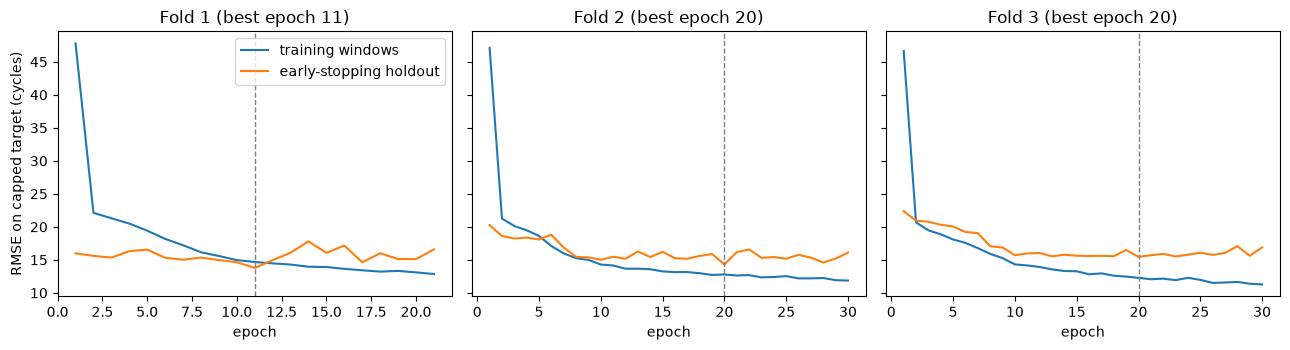

In [6]:
capped = results["capped at 125"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, fold in zip(axes, capped.folds):
    hist = pd.DataFrame(fold.history)
    ax.plot(hist["epoch"], np.sqrt(hist["train_loss"]) * 125, label="training windows")
    ax.plot(hist["epoch"], hist["val_rmse"], label="early-stopping holdout")
    ax.axvline(fold.best_epoch, color="grey", ls="--", lw=1)
    ax.set(title=f"Fold {fold.fold} (best epoch {fold.best_epoch})", xlabel="epoch")
axes[0].set_ylabel("RMSE on capped target (cycles)")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES / "fd001_lstm_learning_curves.png", dpi=150)
plt.show()

## 5. Held-out predictions

Every held-out cycle, coloured by fold. With the capped target, predictions level off at about 100–130 once the true RUL passes the cap, so the largest errors sit at early cycles, outside the selection band. Inside the band, the capped model tends to overestimate RUL between about 40 and 100 cycles. The uncapped model has to guess a large RUL from an engine that still looks healthy, and its predictions spread widely once the true RUL is above about 100.

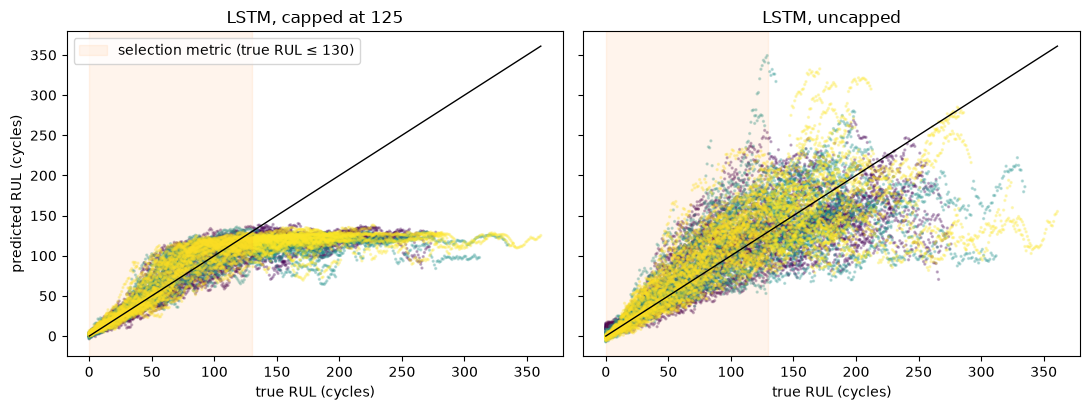

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, (label, cv) in zip(axes, results.items()):
    p = cv.predictions
    ax.scatter(p["rul"], p["prediction"], s=2, alpha=0.25, c=p["fold"], cmap="viridis")
    lim = [0, p["rul"].max()]
    ax.plot(lim, lim, color="black", lw=1)
    ax.axvspan(0, 130, color="tab:orange", alpha=0.08, label="selection metric (true RUL ≤ 130)")
    ax.set(title=f"LSTM, {label}", xlabel="true RUL (cycles)")
axes[0].set_ylabel("predicted RUL (cycles)")
axes[0].legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "fd001_lstm_heldout_predictions.png", dpi=150)
plt.show()

## 6. Summary

- **Chosen setting:** one LSTM layer of 64 units with dropout 0.3 on the final hidden state. Selection RMSE 15.78 ± 0.44 over the 3 folds, with 20,801 parameters. No other setting came within one standard deviation of it.
- **Depth didn't help:** at every width and dropout, two layers scored worse than one, which fits the small training set.
- **Target:** the capped target is clearly better near failure (selection RMSE 15.78 against 30.79 uncapped; late-stage RMSE 9.43 against 14.28). #55 finds the same for all three ML models.
- `configs/lstm.yaml` holds the chosen setting. The regularization study (#66), the ablations (#69) and both hybrids (#64, #65) start from it.
- These are cross-validation scores on training engines. The official test comparison happens once, in #71.